# K-SPADA Prediction and Visualization

[Project overview](../README.md) · [01 Data preparation](./01_data_preparation.ipynb) · [02 Model training](./02_model_training.ipynb) · [03 Prediction and visualization](./03_prediction_and_visualization.ipynb) · [04 Quantile binning](./04_binning_data_preparation.ipynb)

This tutorial loads a trained model, predicts one generic query sample, and creates spatial ground-truth and prediction plots.

Run this notebook from the `tutorials/` directory after [model training](./02_model_training.ipynb). This example predicts query sample 17 using `../outputs/model_training/example_model/model-9.pth`. Predictions and spatial figures are saved under `../outputs/prediction/`.

Executed on 2026-11-10 with **Python (KSPADA_env @ d05 GPU 3)**. The kernel ran on `d05` with GPU 3 selected. The existing prediction implementation selects CPU internally; its device selection was preserved.


In [1]:
from pathlib import Path
import KSPADA

PROJECT_ROOT = Path("..").resolve()
DATA_DIR = PROJECT_ROOT / "outputs" / "liver_cancer_data_preparation"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "prediction"
MODEL_DIR = PROJECT_ROOT / "outputs" / "model_training" / "example_model"
MODEL_WEIGHT_PATH = MODEL_DIR / "model-9.pth"
QUERY_SAMPLE = "17"
QUERY_H5AD = DATA_DIR / "query_data_batch_17_path_scores_graph_k_2.h5ad"
REFERENCE_H5AD = DATA_DIR / "reference_data.h5ad"
PREDICTION_H5AD = OUTPUT_DIR / "query_prediction.h5ad"
FIGURE_PREFIX = OUTPUT_DIR / "query_prediction_spatial"

PREDICTION_CUTOFF = 0.1
USE_GCN = True
UNANNOTATED_TOKENS = 1
PREDICTION_BATCH_SIZE = 50
EMBEDDING_DIM = 48
TRANSFORMER_DEPTH = 2
ATTENTION_HEADS = 4
POINT_SIZE = 50

## Step 1 — Validate input paths

**Execution result:** the model directory, `model-9.pth`, query graph, and reference dataset all existed. The query and training graphs contain the same 3,000 genes in exactly the same order.


In [2]:
for required_path in [MODEL_DIR, MODEL_WEIGHT_PATH, QUERY_H5AD, REFERENCE_H5AD]:
    if not required_path.exists():
        raise FileNotFoundError(required_path)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Step 2 — Predict the query sample

**Execution result:** predictions were saved for all **3,437 cells** in sample 17 to `../outputs/prediction/query_prediction.h5ad`.

| Predicted cell type | Cells |
| --- | ---: |
| Immune | 54 |
| Normal | 255 |
| Stromal | 502 |
| Tumor | 2,626 |


In [3]:
prediction_adata = KSPADA.predict_model(
    adata_input=QUERY_H5AD,
    model_dir=MODEL_DIR,
    model_weight_path=MODEL_WEIGHT_PATH,
    output_path=PREDICTION_H5AD,
    prediction_batches=[QUERY_SAMPLE],
    cutoff=PREDICTION_CUTOFF,
    use_gcn=USE_GCN,
    n_unannotated=UNANNOTATED_TOKENS,
    batch_size=PREDICTION_BATCH_SIZE,
    embed_dim=EMBEDDING_DIM,
    depth=TRANSFORMER_DEPTH,
    num_heads=ATTENTION_HEADS,
)

cpu
depth: 2
num_heads: 4
embed_dim: 48
use_gcn: True
prediction_mode: full_graph
neighbor: 6
edge_index shape: torch.Size([2, 20622])
edge_index after merge shape: torch.Size([2, 20793])
use_position_encode: False
embed_dim_heads: 48
num_heads: 4


## Step 3 — Create spatial plots

**Execution result:** the spatial comparison is embedded in the output below. All exports were verified: [PNG](../outputs/prediction/query_prediction_spatial.png), [PDF](../outputs/prediction/query_prediction_spatial.pdf), and [SVG](../outputs/prediction/query_prediction_spatial.svg). The PNG is 11,941 × 5,929 pixels at 600 DPI.


/home/lixiangyu/anaconda3/envs/KSPADA_env/lib/python3.8/site-packages/anndata/_core/anndata.py:1838: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


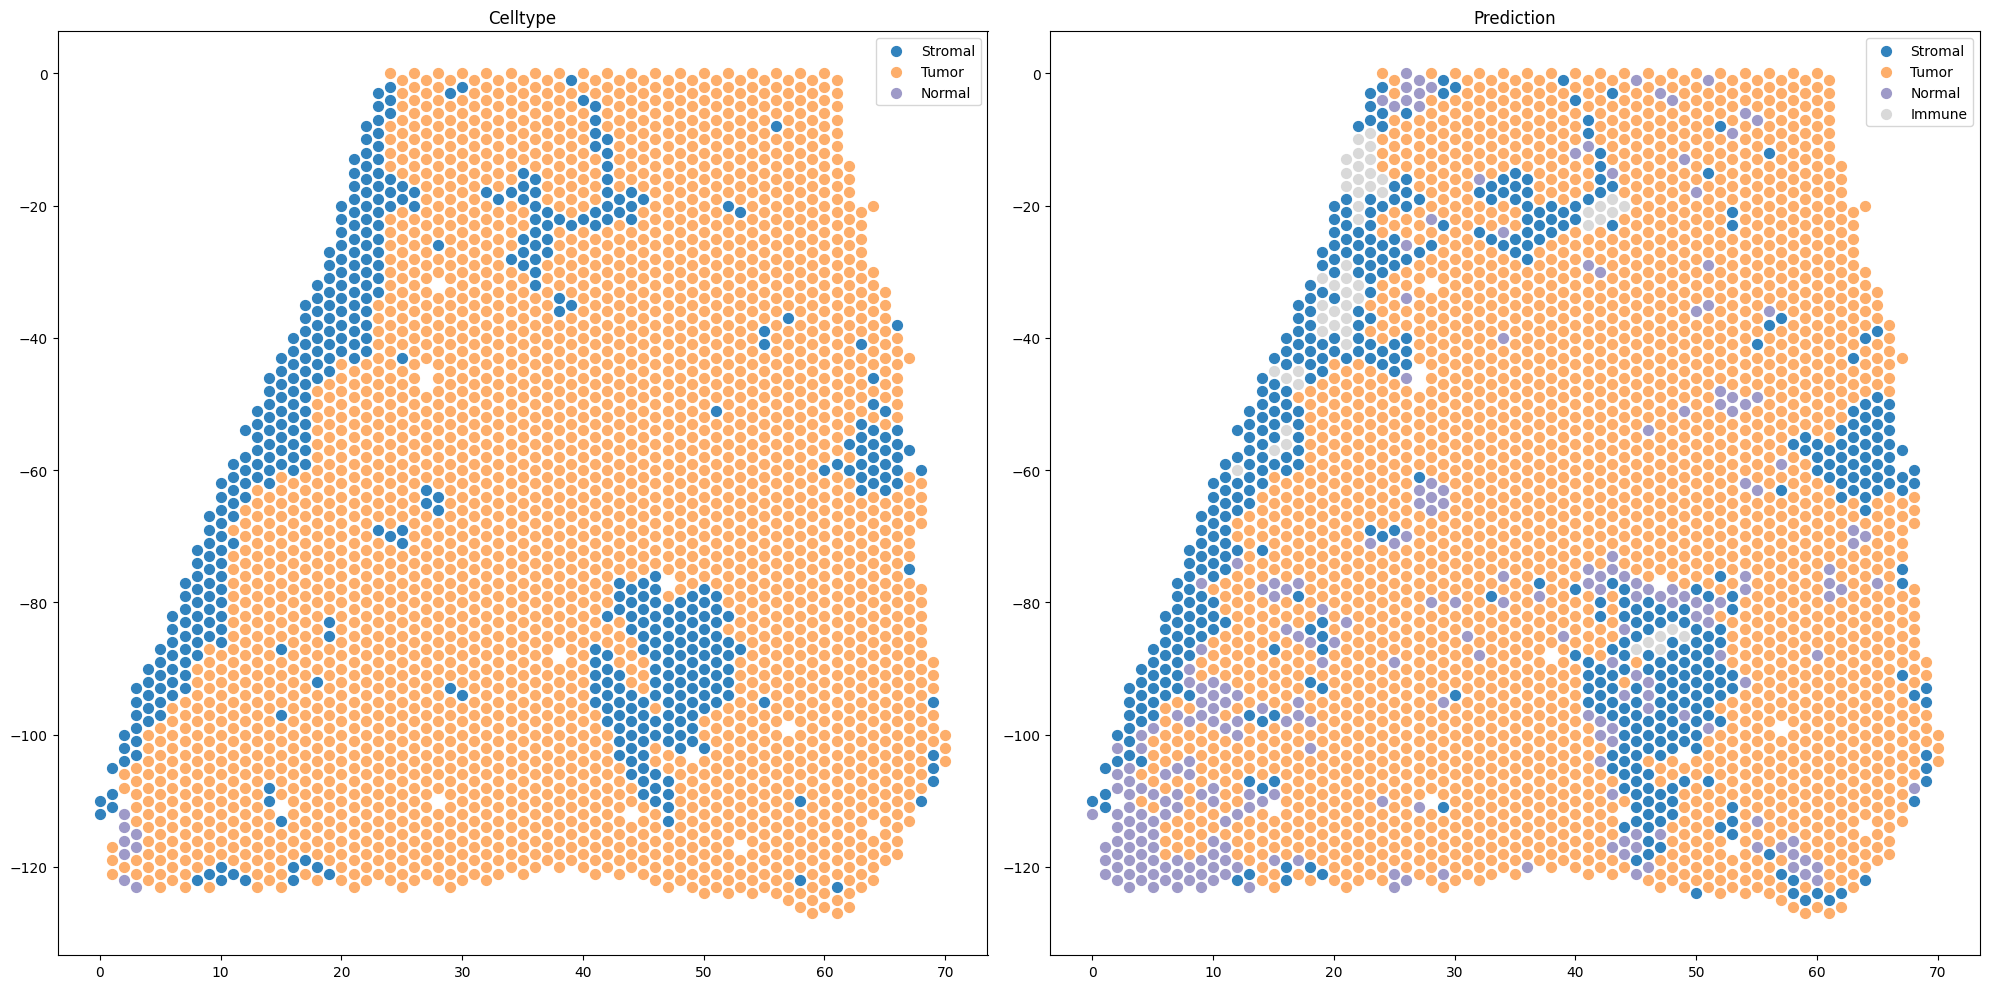

In [4]:
figure, axes, label_colors = KSPADA.plot_prediction_spatial(
    prediction_adata,
    output_prefix=FIGURE_PREFIX,
    reference_adata=REFERENCE_H5AD,
    point_size=POINT_SIZE,
)

## Notes

- Query genes must match the model gene names and gene order.
- Replace `QUERY_SAMPLE` with the value stored in `adata.obs["batch"]` for the query graph.